# Modelo de ojos: abierto / cerrado

Decide si un ojo está **abierto o cerrado**. 

En el juego se aplica a cada ojo por separado en cada fotograma:
- **Guiño**: esquive rápido hacia ese lado.
- **Los dos ojos cerrados más de 0,6 s**: carga de la bomba de pulso.

**Datos**
- Entrenamiento y validación: **CEW**, recortes de ojo de 24×24 en gris.
- Test externo: ojos *Open/Closed* del **Drowsiness dataset** de Kaggle, de otras personas y otras cámaras.

**Métodos comparados**
1. Píxeles + KNN (referencia mínima)
2. HOG + SVM
3. LBP + SVM
4. CNN pequeña entrenada desde cero

Las funciones comunes (descriptores, CNN, k-fold, latencia y guardado) están en `utilidades_gestos.py`, para que el juego use exactamente el mismo preprocesado.

In [ ]:
import re
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage.feature import hog, local_binary_pattern
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

from utilidades_gestos import (carga_dataset, kfold_agrupado, tabla_resultados, metricas,
                               mide_latencia, ModeloGesto, crea_cnn, como_tensor)

CLASES = ['abierto', 'cerrado'] # etiqueta 1 = cerrado (clase positiva)
TAM = 24
ECUALIZAR = True
FIGURAS = 'figuras'

---

## 1. Carga de datos y agrupación por persona

Cada imagen de CEW tiene su pareja. Si un ojo quedara en entrenamiento y su pareja en test, el modelo estaría evaluándose con una persona que ya ha visto y el resultado saldría **optimista**.

Por eso a cada imagen se le asigna un **grupo** (la persona) y el k-fold se hace con `StratifiedGroupKFold`, que mantiene juntos todos los ojos de un mismo grupo:
- Ojos abiertos (`Aaron_Guiel_0001_L.jpg`): el grupo es el nombre de la persona.
- Ojos cerrados (`cerrado_0033_c34_L.jpg`): el grupo es el número de foto original.

**Preprocesado**: además de pasar a gris y a 24×24, se **ecualiza el histograma** de cada imagen. Así todas las imágenes aprovechan todo el rango de grises y se reducen las diferencias de iluminación entre cámaras

Imágenes: (4846, 24, 24) | por clase: {'abierto': np.int64(2462), 'cerrado': np.int64(2384)}
Grupos (personas / fotos) distintos: 2365


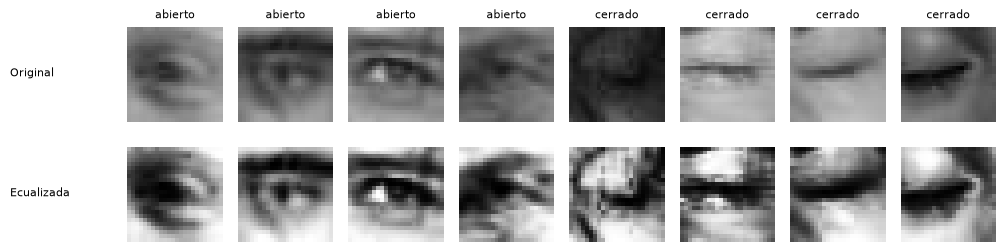

In [ ]:
def grupo_ojo(nombre):
    """Persona de cada ojo: nombre de la persona (abiertos) o número de foto original (cerrados)."""
    if nombre.startswith('cerrado_'):
        return re.sub(r'_c\d+_[LR]\.jpg$', '', nombre)
    return re.sub(r'_\d{4}_[LR]\.jpg$', '', nombre)

X, y, grupos, rutas = carga_dataset('datasets/ojos_CEW', CLASES, TAM, grupo_de=grupo_ojo, ecualizar=ECUALIZAR)
X_sin_ecualizar, _, _, _ = carga_dataset('datasets/ojos_CEW', CLASES, TAM, grupo_de=grupo_ojo)

print('Imágenes:', X.shape, '| por clase:', dict(zip(CLASES, np.bincount(y))))
print('Grupos (personas / fotos) distintos:', len(set(grupos)))

fig, axs = plt.subplots(2, 8, figsize=(10, 2.8))
for col, i in enumerate(np.linspace(0, len(X) - 1, 8).astype(int)):
    axs[0, col].imshow(X_sin_ecualizar[i], cmap='gray', vmin=0, vmax=255)
    axs[1, col].imshow(X[i], cmap='gray', vmin=0, vmax=255)
    axs[0, col].set_title(CLASES[y[i]], fontsize=8)
    axs[0, col].axis('off'); axs[1, col].axis('off')

axs[0, 0].text(-30, 12, 'Original', fontsize=8)
axs[1, 0].text(-30, 12, 'Ecualizada', fontsize=8)

plt.tight_layout()
plt.savefig(f'{FIGURAS}/ojos_ecualizacion.png', dpi=120)
plt.show()

---

## 2. Descriptores HOG vs LBP

- **HOG** describe la orientación de los bordes en cada celda. Un ojo cerrado es casi una línea horizontal, mientras que uno abierto tiene bordes curvos alrededor del iris.
- **LBP** describe la textura local comparando cada píxel con sus 8 vecinos.

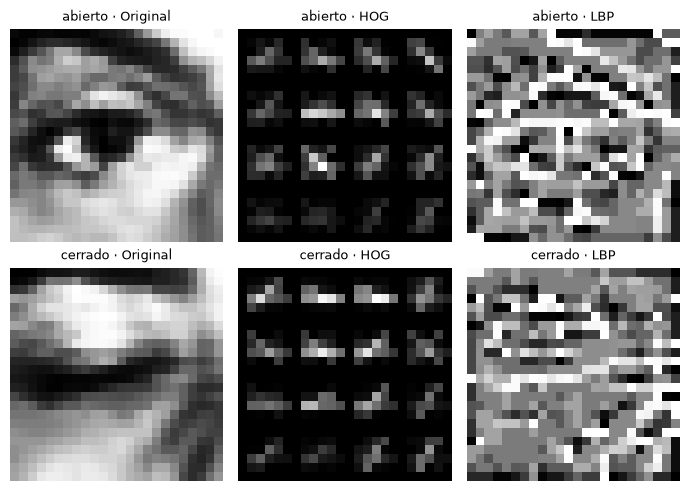

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(7, 5))

for fila, etiqueta in enumerate([0, 1]):
    img = X[np.where(y == etiqueta)[0][7]]
    _, vis_hog = hog(img, orientations=9, pixels_per_cell=(6, 6), cells_per_block=(2, 2), visualize=True)
    lbp = local_binary_pattern(img, 8, 1, method='nri_uniform')
    
    for ax, im, titulo in zip(axs[fila], [img, vis_hog, lbp], ['Original', 'HOG', 'LBP']):
        ax.imshow(im, cmap='gray')
        ax.set_title(f'{CLASES[etiqueta]} · {titulo}', fontsize=9)
        ax.axis('off')
        
plt.tight_layout()
plt.savefig(f'{FIGURAS}/ojos_descriptores.png', dpi=120)
plt.show()

---

## 3. Validación cruzada k-fold agrupada por persona

En cada fold se entrena con 4/5 de las personas y se evalúa con el 1/5 restante, que el modelo no ha visto nunca. 

Para las SVM, `C` y `gamma` se eligen con una búsqueda en rejilla dentro de los datos de entrenamiento de cada fold.

La CNN (3 capas convolucionales, unos 27.500 parámetros) se entrena 30 épocas con **aumento de datos**: en cada época, cada ojo se voltea, desplaza, amplía/reduce y cambia de brillo y contraste al azar. Así la red ve muchas variantes de cada ojo y aprende a no depender del encuadre o la luz exactos.

Las métricas se calculan respecto a la clase **cerrado**:
- **Precisión**: de las veces que dice "cerrado", cuántas lo eran. Si es baja, el juego dispararía acciones sin querer.
- **Recall**: de los ojos cerrados, cuántos detecta. Si es bajo, al jugador "no le hace caso".

In [4]:
METODOS = ['Píxeles + KNN', 'HOG + SVM', 'LBP + SVM', 'CNN']
res = kfold_agrupado(X, y, grupos, METODOS, k=5)
print()
tabla_resultados(res)

Fold 1: Píxeles + KNN F1=0.859 | HOG + SVM F1=0.910 | LBP + SVM F1=0.947 | CNN F1=0.949
Fold 2: Píxeles + KNN F1=0.851 | HOG + SVM F1=0.903 | LBP + SVM F1=0.952 | CNN F1=0.950
Fold 3: Píxeles + KNN F1=0.863 | HOG + SVM F1=0.896 | LBP + SVM F1=0.948 | CNN F1=0.935
Fold 4: Píxeles + KNN F1=0.864 | HOG + SVM F1=0.917 | LBP + SVM F1=0.935 | CNN F1=0.951
Fold 5: Píxeles + KNN F1=0.824 | HOG + SVM F1=0.905 | LBP + SVM F1=0.942 | CNN F1=0.929

Método                 Accuracy       Precisión          Recall              F1
Píxeles + KNN     0.852 ± 0.016   0.835 ± 0.019   0.871 ± 0.013   0.852 ± 0.015
HOG + SVM         0.908 ± 0.007   0.908 ± 0.012   0.905 ± 0.014   0.906 ± 0.007
LBP + SVM         0.946 ± 0.006   0.939 ± 0.009   0.951 ± 0.007   0.945 ± 0.006
CNN               0.944 ± 0.009   0.946 ± 0.029   0.940 ± 0.031   0.943 ± 0.009


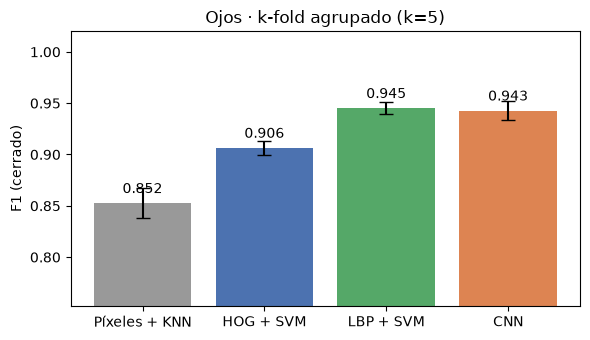

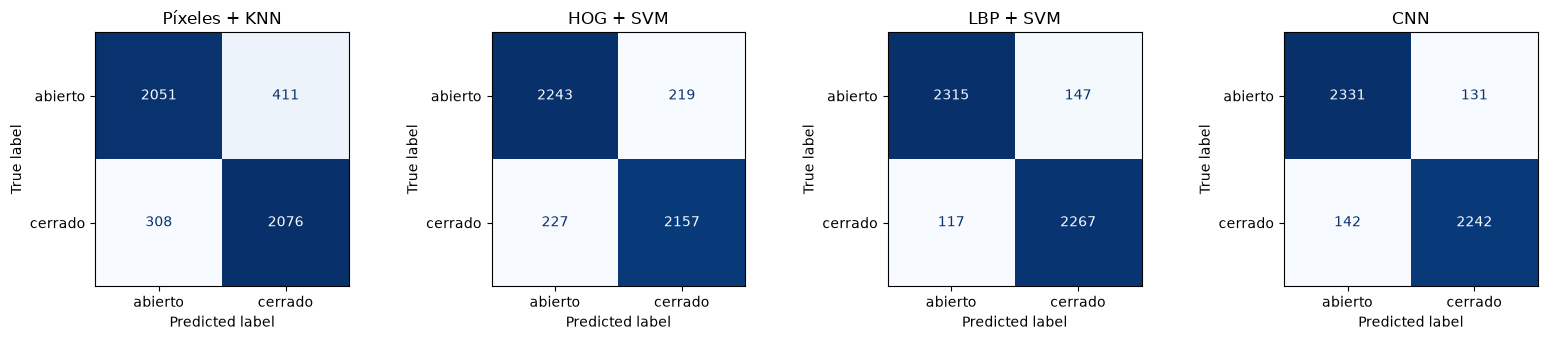

In [ ]:
# F1 medio por método (barras de error = desviación entre folds)
f1, f1_std = [], []
for m in METODOS:
    valores_f1 = []
    for f in res[m]['folds']:
        valores_f1.append(f['f1'])

    f1.append(np.mean(valores_f1))
    f1_std.append(np.std(valores_f1))

plt.figure(figsize=(6, 3.5))
plt.bar(METODOS, f1, yerr=f1_std, capsize=5, color=['#999999', '#4C72B0', '#55A868', '#DD8452'])

for i, v in enumerate(f1):
    plt.text(i, v + 0.01, f'{v:.3f}', ha='center')
    
plt.ylim(min(f1) - 0.1, 1.02)
plt.ylabel('F1 (cerrado)')
plt.title('Ojos · k-fold agrupado (k=5)')
plt.tight_layout()
plt.savefig(f'{FIGURAS}/ojos_kfold_f1.png', dpi=120)
plt.show()

# Matrices de confusión acumuladas en los 5 folds
fig, axs = plt.subplots(1, len(METODOS), figsize=(4 * len(METODOS), 3.5))
for ax, m in zip(axs, METODOS):
    ConfusionMatrixDisplay(res[m]['cm'], display_labels=CLASES).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(m)
plt.tight_layout()
plt.savefig(f'{FIGURAS}/ojos_kfold_confusion.png', dpi=120)
plt.show()

---

## 4. Test externo con otro dataset

El k-fold mide cómo se comporta el modelo con **personas nuevas del mismo dataset**. Pero en el juego las imágenes vendrán de la webcam, con otra cámara, otra luz y otro encuadre. Para estimar esa capacidad de **generalización**, se entrenan los modelos con **todo CEW** y se evalúan con los ojos del dataset de Kaggle, que no se han usado para nada.

### 4.1 Efecto del encuadre

Los recortes de Kaggle son **más amplios** que los de CEW. Para medir cuánto afecta, se evalúa con la imagen completa y con un recorte central del 80 %, que se parece más al encuadre de CEW.

Test externo: (1452, 24, 24) {'abierto': np.int64(726), 'cerrado': np.int64(726)}


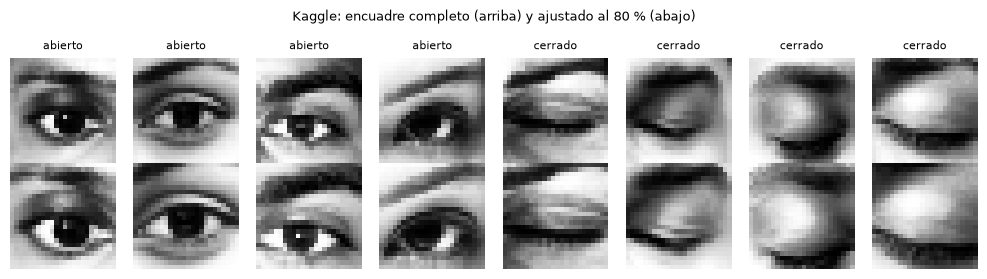

In [ ]:
ENCUADRES = {'completo': 1.0, 'ajustado (80 %)': 0.8}
test_ext = {}

for nombre_enc, fraccion in ENCUADRES.items():
    Xk, yk, _, rutas_k = carga_dataset('datasets/ojos_kaggle', CLASES, TAM, ecualizar=ECUALIZAR, fraccion=fraccion)
    test_ext[nombre_enc] = (Xk, yk)

print('Test externo:', Xk.shape, dict(zip(CLASES, np.bincount(yk))))

fig, axs = plt.subplots(2, 8, figsize=(10, 2.8))

for col, i in enumerate(np.linspace(0, len(yk) - 1, 8).astype(int)):
    for fila, nombre_enc in enumerate(ENCUADRES):
        axs[fila, col].imshow(test_ext[nombre_enc][0][i], cmap='gray', vmin=0, vmax=255)
        axs[fila, col].axis('off')
    axs[0, col].set_title(CLASES[yk[i]], fontsize=8)
    
plt.suptitle('Kaggle: encuadre completo (arriba) y ajustado al 80 % (abajo)', fontsize=9)
plt.tight_layout()
plt.savefig(f'{FIGURAS}/ojos_kaggle_encuadre.png', dpi=120)
plt.show()

### 4.2 Modelos finales entrenados con todo CEW

Se entrena una **CNN sin aumento de datos** para ver cuánto aporta el aumento a la generalización.

In [ ]:
import tensorflow as tf

modelos = {}
for tipo, nombre in [('hog', 'HOG + SVM'), ('lbp', 'LBP + SVM'), ('cnn', 'CNN')]:
    modelos[nombre] = ModeloGesto.entrena(tipo, X, y, TAM, True, CLASES, ecualizar=ECUALIZAR)

tf.keras.utils.set_random_seed(0)
red = crea_cnn(TAM, 1, aumento=False)
red.fit(como_tensor(X), y, epochs=30, batch_size=64, verbose=0)
cnn_sin_aumento = ModeloGesto('cnn', red, TAM, True, CLASES, ECUALIZAR)

res_ext = {}
print(f"{'Método':22s} {'Encuadre':16s} {'Accuracy':>9s} {'Precisión':>10s} {'Recall':>8s} {'F1':>7s}")

for nombre, mg in {**modelos, 'CNN sin aumento': cnn_sin_aumento}.items():
    for nombre_enc, (Xk, yk) in test_ext.items():
        p = mg.prob_lote(Xk)
        r = {'p': p, **metricas(yk, (p >= 0.5).astype(int))}
        res_ext[(nombre, nombre_enc)] = r
        print(f"{nombre:22s} {nombre_enc:16s} {r['accuracy']:9.3f} {r['precision']:10.3f} "
              f"{r['recall']:8.3f} {r['f1']:7.3f}")

Método                 Encuadre          Accuracy  Precisión   Recall      F1
HOG + SVM              completo             0.579      0.960    0.164   0.280
HOG + SVM              ajustado (80 %)      0.601      0.915    0.223   0.359
LBP + SVM              completo             0.694      0.774    0.548   0.642
LBP + SVM              ajustado (80 %)      0.712      0.699    0.744   0.721
CNN                    completo             0.913      0.993    0.831   0.905
CNN                    ajustado (80 %)      0.980      0.994    0.966   0.980
CNN sin aumento        completo             0.937      0.940    0.934   0.937
CNN sin aumento        ajustado (80 %)      0.946      0.908    0.992   0.948


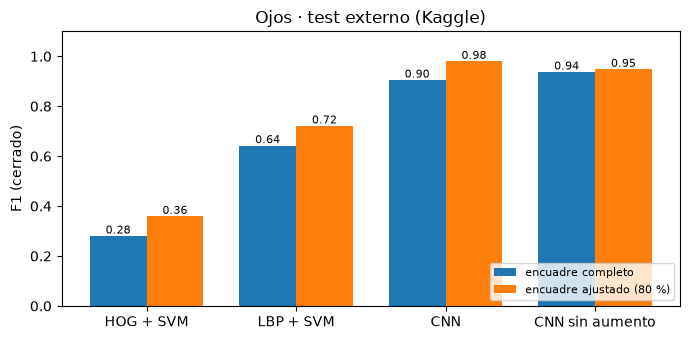

In [ ]:
nombres = list(modelos) + ['CNN sin aumento']
ancho = 0.38

plt.figure(figsize=(7, 3.5))

for j, nombre_enc in enumerate(ENCUADRES):
    valores = []
    for n in nombres:
        valores.append(res_ext[(n, nombre_enc)]['f1'])
    xs = np.arange(len(nombres)) + (j - 0.5) * ancho
    plt.bar(xs, valores, ancho, label=f'encuadre {nombre_enc}')
    for xi, v in zip(xs, valores):
        plt.text(xi, v + 0.01, f'{v:.2f}', ha='center', fontsize=8)

plt.xticks(range(len(nombres)), nombres)
plt.ylim(0, 1.1)
plt.ylabel('F1 (cerrado)')
plt.title('Ojos · test externo (Kaggle)')
plt.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig(f'{FIGURAS}/ojos_externo_f1.png', dpi=120)
plt.show()

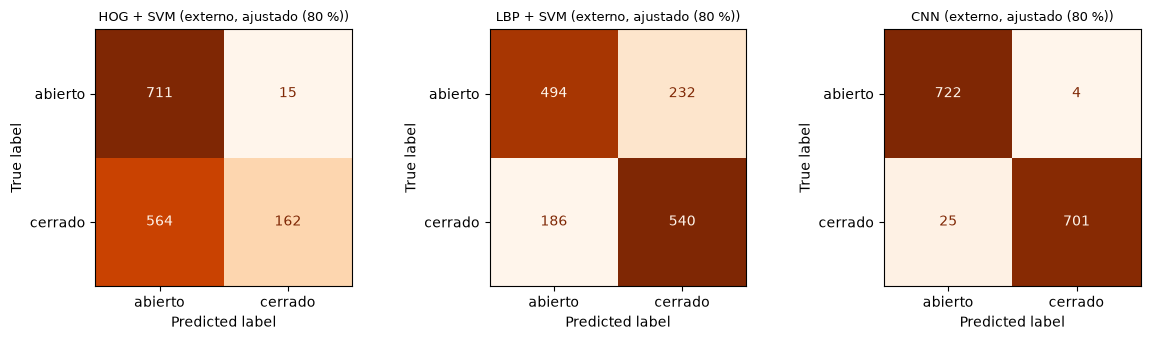

In [ ]:
# Matrices de confusión en el test externo (encuadre ajustado)
ENC = 'ajustado (80 %)'
Xk, yk = test_ext[ENC]

fig, axs = plt.subplots(1, len(modelos), figsize=(4 * len(modelos), 3.5))

for ax, nombre in zip(axs, modelos):
    cm = confusion_matrix(yk, (res_ext[(nombre, ENC)]['p'] >= 0.5).astype(int), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, colorbar=False, cmap='Oranges')
    ax.set_title(f'{nombre} (externo, {ENC})', fontsize=9)
    
plt.tight_layout()
plt.savefig(f'{FIGURAS}/ojos_externo_confusion.png', dpi=120)
plt.show()

CNN: 29 errores de 1452


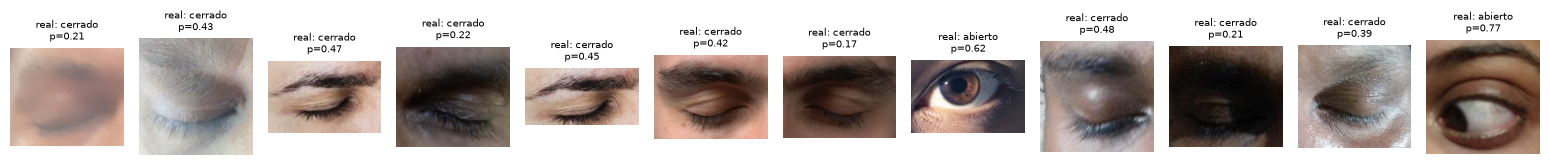

In [ ]:
# Ejemplos mal clasificados por la CNN en el test externo (encuadre ajustado)
p = res_ext[('CNN', ENC)]['p']
errores = np.where((p >= 0.5).astype(int) != yk)[0]
print(f'CNN: {len(errores)} errores de {len(yk)}')
n = min(12, len(errores))

if n:
    sel = np.random.default_rng(0).choice(errores, n, replace=False)
    fig, axs = plt.subplots(1, n, figsize=(n * 1.3, 1.9))
    for ax, i in zip(np.atleast_1d(axs), sel):
        ax.imshow(cv2.cvtColor(cv2.imread(rutas_k[i]), cv2.COLOR_BGR2RGB))
        ax.set_title(f'real: {CLASES[yk[i]]}\np={p[i]:.2f}', fontsize=7)
        ax.axis('off')
        
    plt.tight_layout()
    plt.savefig(f'{FIGURAS}/ojos_externo_errores.png', dpi=120)
    plt.show()

---

## 5. Latencia

En el juego hay que clasificar **2 ojos por fotograma**, además de la boca y la sonrisa y de ejecutar MediaPipe. 

A 30 FPS hay unos 33 ms por fotograma para todo, así que interesa que cada clasificación tarde muy poco. Se mide el tiempo de clasificar **una imagen cada vez**.

In [ ]:
latencias = {}
for nombre, mg in modelos.items():
    latencias[nombre] = mide_latencia(mg, Xk[:300])

for nombre, ms in latencias.items():
    print(f'{nombre:12s} {ms:6.2f} ms por ojo  ->  {2 * ms:6.2f} ms por fotograma (2 ojos)')

HOG + SVM      1.28 ms por ojo  ->    2.55 ms por fotograma (2 ojos)
LBP + SVM      2.05 ms por ojo  ->    4.10 ms por fotograma (2 ojos)
CNN            0.90 ms por ojo  ->    1.79 ms por fotograma (2 ojos)


---

## 6. Modelo elegido

**Criterio de elección**: el modelo con mayor F1 en el **test externo con encuadre ajustado**, porque es la medida que más se parece al uso real. 

Se comprueba además que su latencia permite clasificar los dos ojos en cada fotograma.

- `figuras/ojos_resumen.png`: comparación de métodos con el elegido resaltado con una estrella.
- `resultados/ojos_resumen.md` y `.json`: tabla, modelo elegido y motivo, listos para el README.

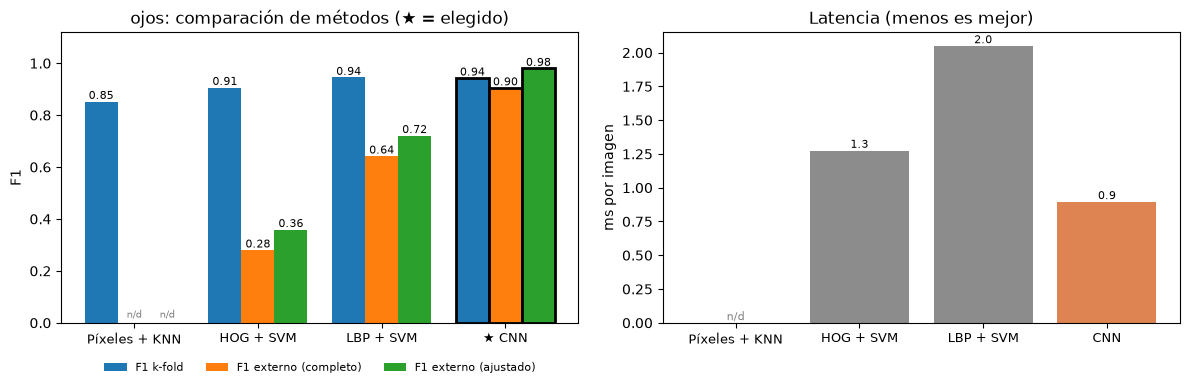

## Modelo de ojos

| Método | F1 k-fold | F1 externo (completo) | F1 externo (ajustado) | ms por imagen |
|---|---|---|---|---|
| Píxeles + KNN | 0.852 | — | — | — |
| HOG + SVM | 0.906 | 0.280 | 0.359 | 1.3 |
| LBP + SVM | 0.945 | 0.642 | 0.721 | 2.0 |
| **CNN** ★ | 0.943 | 0.905 | 0.980 | 0.9 |

**Modelo elegido:** CNN

**Motivo:** Es el que mejor generaliza a otra cámara: F1 externo 0.980 con encuadre ajustado frente a 0.721 del siguiente (LBP + SVM), con un F1 en k-fold de 0.943 y 0.9 ms por ojo, suficiente para clasificar los dos ojos en cada fotograma.

Guardado: figuras\ojos_resumen.png, resultados/ojos_resumen.md y .json
Modelos guardados en modelos/  ->  el juego usará modelos/ojos_cnn


In [ ]:
from utilidades_gestos import guarda_resumen, f1_medio

filas = [{'Método': 'Píxeles + KNN', 'F1 k-fold': f1_medio(res, 'Píxeles + KNN')[0],
          'F1 externo (completo)': None, 'F1 externo (ajustado)': None, 'ms': None}]

for nombre in modelos:
    filas.append({'Método': nombre,
                  'F1 k-fold': f1_medio(res, nombre)[0],
                  'F1 externo (completo)': res_ext[(nombre, 'completo')]['f1'],
                  'F1 externo (ajustado)': res_ext[(nombre, ENC)]['f1'],
                  'ms': latencias[nombre]})

elegido, f1_elegido = None, -1
for n in modelos:
    if res_ext[(n, ENC)]['f1'] > f1_elegido:
        elegido, f1_elegido = n, res_ext[(n, ENC)]['f1']

otro, f1_otro = None, -1
for n in modelos:
    if n != elegido and res_ext[(n, ENC)]['f1'] > f1_otro:
        otro, f1_otro = n, res_ext[(n, ENC)]['f1']

motivo = (f"Es el que mejor generaliza a otra cámara: F1 externo {res_ext[(elegido, ENC)]['f1']:.3f} "
          f"con encuadre ajustado frente a {res_ext[(otro, ENC)]['f1']:.3f} del siguiente ({otro}), "
          f"con un F1 en k-fold de {f1_medio(res, elegido)[0]:.3f} y {latencias[elegido]:.1f} ms por ojo, "
          f"suficiente para clasificar los dos ojos en cada fotograma.")

guarda_resumen('ojos', filas, elegido, motivo,
               ['F1 k-fold', 'F1 externo (completo)', 'F1 externo (ajustado)'])

for nombre, mg in modelos.items():
    mg.guarda(f"modelos/ojos_{mg.tipo}")
    
print('Modelos guardados en modelos/  ->  el juego usará modelos/ojos_' + modelos[elegido].tipo)

---

## 7. Facilidad de uso y coste

Comparamos los modelos clásicos y las redes neuronales no solo por sus resultados, sino también por su **facilidad de uso** y su **rapidez**. 

Para cada método se recoge:

- **Tiempo de entrenamiento** medio por fold, incluida la búsqueda en rejilla de la SVM.
- **Tiempo de predicción** por imagen del modelo final, que es lo que importa en el juego.
- **Tamaño** del modelo guardado.
- **Qué hay que ajustar** para usarlo.

Se guarda en `resultados/ojos_facilidad.md` y `figuras/ojos_facilidad.png`.

## Facilidad de uso y coste: ojos

| Método | Entrenamiento por fold (s) | Predicción (ms/imagen) | Tamaño (MB) | Qué hay que ajustar | Observaciones |
|---|---|---|---|---|---|
| Píxeles + KNN | 0.1 | — | — | k (vecinos) | No entrena: guarda todas las imágenes y compara con todas al predecir. |
| HOG + SVM | 10.5 | 1.3 | 4.58 | celdas, orientaciones, bloques + C y gamma (rejilla) | Hay que diseñar el descriptor; la búsqueda en rejilla de la SVM multiplica el tiempo de entrenamiento. |
| LBP + SVM | 19.6 | 2.0 | 8.45 | celdas, vecinos, radio, tipo de patrón + C y gamma (rejilla) | Igual que HOG; el descriptor es más lento de calcular. |
| CNN | 12.2 | 0.9 | 0.39 | arquitectura, épocas, lote, optimizador, aumento de datos | No hay que diseñar descriptores, pero sí la red; necesita TensorFlow. Su tiempo de entrenamiento depende de las épocas, no del número de vectores soporte, y en CPU es similar al de la SVM con búsqueda en rejilla. |


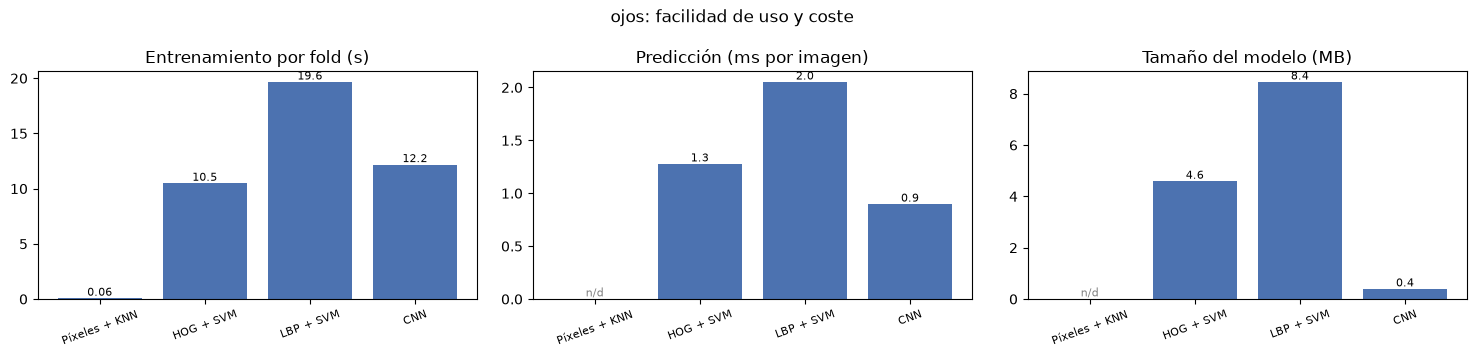

In [13]:
from utilidades_gestos import tabla_facilidad
facilidad = tabla_facilidad('ojos', res, latencias)

---

## 8. Conclusiones

| Método | F1 k-fold (CEW) | F1 externo, encuadre completo | F1 externo, encuadre ajustado | ms por ojo |
|---|---|---|---|---|
| Píxeles + KNN | 0,852 ± 0,015 | — | — | — |
| HOG + SVM | 0,906 ± 0,007 | 0,280 | 0,359 | 1,3 |
| LBP + SVM | **0,945 ± 0,006** | 0,642 | 0,721 | 2,0 |
| CNN (con aumento) | 0,943 ± 0,009 | **0,905** | **0,980** | 0,9 |
| CNN sin aumento | — | 0,937 | 0,948 | — |

La comparación final de métodos y el modelo elegido quedan guardados en `figuras/ojos_resumen.png` y `resultados/ojos_resumen.md`.

1. **Dentro de CEW, LBP + SVM y la CNN empatan** (F1 ≈ 0,94), muy por encima de los píxeles con KNN (0,85). Los descriptores locales clásicos funcionan muy bien cuando los datos de test se parecen a los de entrenamiento.
2. **En el test externo la diferencia es enorme.** HOG + SVM se hunde (F1 0,28): casi nunca detecta los ojos cerrados de Kaggle (recall 0,16), porque las orientaciones de los bordes cambian mucho con otra resolución y encuadre. LBP + SVM aguanta algo mejor (0,64–0,72). La CNN mantiene un F1 de 0,90–0,98. **El k-fold, aunque esté bien agrupado por persona, no basta para predecir cómo funcionará el modelo con otra cámara**; por eso es importante el test externo.
3. **El encuadre importa**: ajustar el recorte para que se parezca al de CEW mejora todos los modelos (la CNN pasa de 0,905 a 0,980). 
    * **Consecuencia para el juego**: el recorte del ojo a partir de los landmarks de MediaPipe debe imitar el encuadre de CEW (ojo centrado y ajustado, poca ceja).
4. **Aumento de datos**: con el encuadre ajustado, la CNN con aumento es claramente mejor (0,980 frente a 0,948, y con mucha mayor precisión: 0,994 frente a 0,908). Con el encuadre completo, la versión sin aumento sale algo mejor (0,937 frente a 0,905), así que el aumento no compensa del todo un encuadre muy distinto: lo importante sigue siendo recortar bien.
5. **Errores típicos de la CNN**: ojos cerrados muy oscuros o borrosos, recortes en los que la ceja ocupa gran parte de la imagen y primeros planos extremos de ojos abiertos.
6. **Latencia**: todos los modelos son lo bastante rápidos para el juego (los 2 ojos de un fotograma en unos 2–4 ms). Para la CNN fue clave compilar la red con `tf.function`: sin ello tardaba unos 25 ms por ojo.

7. **Facilidad de uso y coste**: entrenar la CNN cuesta unos 12 s por fold, del mismo orden que HOG + SVM (10,5 s) y LBP + SVM (19,6 s) con su búsqueda en rejilla; los píxeles con KNN no entrenan (0,1 s). Al predecir, la CNN es la más rápida (0,9 ms por ojo) y su modelo ocupa **0,39 MB**, frente a 4,6–8,5 MB de las SVM, que guardan miles de vectores soporte. A cambio, los métodos clásicos piden diseñar el descriptor (celdas, orientaciones, radio…) y la CNN pide diseñar la red y elegir épocas y aumento de datos, además de depender de TensorFlow.

> La mejor ha sido la **CNN con aumento de datos** (`modelos/ojos_cnn`), por ser la que mejor generaliza a otra cámara, con una latencia similar a la de los modelos clásicos. LBP + SVM se mantiene como alternativa clásica para la comparación.

---